
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 4</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



# <font color = lightGreen> PART 3 - 6:
 </font>

In [ ]:
!pip install torch

In [1]:
import math
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import namedtuple, deque
import matplotlib.pyplot as plt
import gym
from itertools import count
from gym.wrappers import RecordVideo



In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.05
EPS_DECAY = 1000
TAU = 0.005
LR = 1e-4


In [4]:
class ReplayMemory:
    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [5]:
class DQN(nn.Module):
    def __init__(self, n_observations, n_actions):
        super(DQN, self).__init__()
        self.layer1 = nn.Linear(n_observations, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, n_actions)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)

In [6]:

env = gym.make("CartPole-v1")
n_actions = env.action_space.n
state, _ = env.reset()
n_observations = len(state)

policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
memory = ReplayMemory(10000)
Transition = namedtuple('Transition', ('state', 'action', 'next_state', 'reward'))
steps_done = 0


In [7]:
def select_action(state):
    global steps_done
    sample = random.random()
    eps_threshold = EPS_END + (EPS_START - EPS_END) * math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1
    if sample > eps_threshold:
        with torch.no_grad():
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


In [8]:
def optimize_model():
    if len(memory) < BATCH_SIZE:
        return
    transitions = memory.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))

    non_final_mask = torch.tensor(tuple(map(lambda s: s is not None, batch.next_state)), device=device, dtype=torch.bool)
    non_final_next_states = torch.cat([s for s in batch.next_state if s is not None])
    state_batch = torch.cat(batch.state)
    action_batch = torch.cat(batch.action)
    reward_batch = torch.cat(batch.reward)

    state_action_values = policy_net(state_batch).gather(1, action_batch)

    next_state_values = torch.zeros(BATCH_SIZE, device=device)
    with torch.no_grad():
        next_state_values[non_final_mask] = target_net(non_final_next_states).max(1).values
    expected_state_action_values = (next_state_values * GAMMA) + reward_batch

    criterion = nn.SmoothL1Loss()
    loss = criterion(state_action_values, expected_state_action_values.unsqueeze(1))

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
    optimizer.step()


In [9]:
num_episodes = 500
episode_rewards = []

for i_episode in range(num_episodes):
    if i_episode%20 == 0:
        print("Ep: ", i_episode)
    state, _ = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    total_reward = 0
    for t in count():
        action = select_action(state)
        observation, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward
        reward = torch.tensor([reward], device=device)
        done = terminated or truncated

        if done:
            next_state = None
        else:
            next_state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

        memory.push(state, action, next_state, reward)
        state = next_state

        optimize_model()

        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key] * TAU + target_net_state_dict[key] * (1 - TAU)
        target_net.load_state_dict(target_net_state_dict)

        if done:
            episode_rewards.append(total_reward)
            break

print('Done.')


Ep:  0


C:\Users\AFRAA\AppData\Roaming\Python\Python312\site-packages\gym\utils\passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


Ep:  20
Ep:  40
Ep:  60
Ep:  80
Ep:  100
Ep:  120
Ep:  140
Ep:  160
Ep:  180
Ep:  200
Ep:  220
Ep:  240
Ep:  260
Ep:  280
Ep:  300
Ep:  320
Ep:  340
Ep:  360
Ep:  380
Ep:  400
Ep:  420
Ep:  440
Ep:  460
Ep:  480
Done.


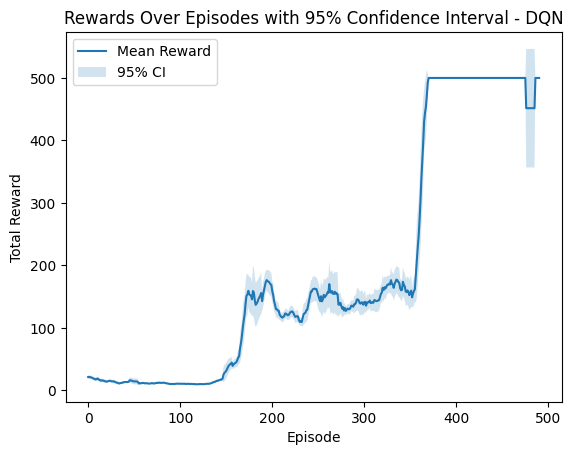

In [12]:
rewards = torch.tensor(episode_rewards, dtype=torch.float)
plt.figure()
plt.title("Rewards Over Episodes with 95% Confidence Interval - DQN")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
average_rewards = rewards.unfold(0, 10, 1).mean(1).numpy()
std_rewards = rewards.unfold(0, 10, 1).std(1).numpy()
plt.plot(range(len(average_rewards)), average_rewards, label="Mean Reward")
plt.fill_between(range(len(average_rewards)),
                 average_rewards - 1.96 * std_rewards / math.sqrt(10),
                 average_rewards + 1.96 * std_rewards / math.sqrt(10),
                 alpha=0.2, label="95% CI")
plt.legend()
plt.show()


In [14]:
video_folder = "./videos_3.6/"

env = gym.make("CartPole-v1", render_mode="rgb_array")
env = RecordVideo(env, video_folder=video_folder, episode_trigger=lambda x: True)

num_test_episodes = 5

for i_episode in range(num_test_episodes):
    state, _ = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    total_reward = 0
    print(f"Recording test episode {i_episode + 1}...")

    for t in count():
        action = select_action(state,)  # Use a deterministic policy for testing
        observation, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward

        state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)
        done = terminated or truncated

        if done:
            print(f"Test episode {i_episode + 1} ended with total reward: {total_reward}")
            break

env.close()
print(f"Videos saved to: {video_folder}")


Recording test episode 1...
Moviepy - Building video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-0.mp4.
Moviepy - Writing video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-0.mp4



Moviepy - Done !
Moviepy - video ready c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-0.mp4
Test episode 1 ended with total reward: 500.0
Recording test episode 2...
Moviepy - Building video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-1.mp4.
Moviepy - Writing video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-1.mp4



Moviepy - Done !
Moviepy - video ready c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-1.mp4
Test episode 2 ended with total reward: 500.0
Recording test episode 3...
Moviepy - Building video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-2.mp4.
Moviepy - Writing video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-2.mp4



Moviepy - Done !
Moviepy - video ready c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-2.mp4
Test episode 3 ended with total reward: 500.0
Recording test episode 4...
Moviepy - Building video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-3.mp4.
Moviepy - Writing video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-3.mp4



Moviepy - Done !
Moviepy - video ready c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-3.mp4
Test episode 4 ended with total reward: 350.0
Recording test episode 5...
Moviepy - Building video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-4.mp4.
Moviepy - Writing video c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-4.mp4



Moviepy - Done !
Moviepy - video ready c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\04\videos_3.6\rl-video-episode-4.mp4
Test episode 5 ended with total reward: 500.0
Videos saved to: ./videos_3.6/
